Celda 1: Importación de librerías y montaje de Google Drive (Base de datos MiBici)

In [ ]:
import os
import glob
import hashlib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Montar Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


Celda 2: Carga masiva de datos desde Google Drive (Paso 1)

In [ ]:
import gc
import os
import glob
import pandas as pd
import numpy as np

# Definir la ruta base donde se encuentran los archivos CSV
base_path = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data'

# 1. Definir ruta de salida en Drive para los archivos intermedios
output_dir_interim = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/interim'
os.makedirs(output_dir_interim, exist_ok=True)

# 2. Búsqueda recursiva y ordenada de archivos CSV
file_pattern = os.path.join(base_path, '**', 'datos_abiertos*.csv')
csv_files = sorted(glob.glob(file_pattern, recursive=True))
total_files = len(csv_files)
print(f"Total de archivos CSV encontrados: {total_files}")

if total_files > 0:
    # Dividir la lista de archivos en 3 partes equitativas
    file_batches = np.array_split(csv_files, 3)

    for part_idx, batch_files in enumerate(file_batches, start=1):
        print(f"\n==========================================")
        print(f" Procesando Parte {part_idx} de 3 ({len(batch_files)} archivos)")
        print(f"==========================================")

        dfs_part = []
        for file_path in batch_files:
            try:
                df_temp = pd.read_csv(file_path, encoding='utf-8')
                dfs_part.append(df_temp)
            except UnicodeDecodeError:
                try:
                    df_temp = pd.read_csv(file_path, encoding='latin-1')
                    dfs_part.append(df_temp)
                except Exception as e:
                    print(f"Error al leer {file_path}: {e}")

        if dfs_part:
            # Concatenar únicamente los dataframes de esta parte
            df_part = pd.concat(dfs_part, ignore_index=True)

            # Liberar inmediatamente la lista temporal
            del dfs_part
            gc.collect()

            # Normalizar nombres de columnas
            df_part.columns = df_part.columns.str.strip()

            # Ruta y guardado de la parte actual
            part_parquet_path = os.path.join(output_dir_interim, f'df_raw_parte_{part_idx}.parquet')
            print(f"Guardando parte {part_idx} en Google Drive...")
            df_part.to_parquet(part_parquet_path, index=False, engine='pyarrow')

            print(f"¡Parte {part_idx} guardada con éxito!")
            print(f"Dimensiones de la Parte {part_idx}: {df_part.shape}")

            # Liberar DataFrame procesado y limpiar RAM
            del df_part
            gc.collect()

    print("\n¡Proceso por partes finalizado con éxito! Se generaron 3 archivos Parquet.")
else:
    print(f"No se encontraron archivos que coincidan con el patrón en {base_path}.")

Total de archivos CSV encontrados: 142

 Procesando Parte 1 de 3 (48 archivos)
Guardando parte 1 en Google Drive...
¡Parte 1 guardada con éxito!
Dimensiones de la Parte 1: (7070178, 8)

 Procesando Parte 2 de 3 (47 archivos)
Guardando parte 2 en Google Drive...
¡Parte 2 guardada con éxito!
Dimensiones de la Parte 2: (14471929, 8)

 Procesando Parte 3 de 3 (47 archivos)
Guardando parte 3 en Google Drive...
¡Parte 3 guardada con éxito!
Dimensiones de la Parte 3: (17536877, 9)

¡Proceso por partes finalizado con éxito! Se generaron 3 archivos Parquet.


In [ ]:
import os
import pandas as pd

# Ruta de la Parte 3 en Drive
file_path_3 = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/interim/df_raw_parte_3.parquet'

print("=== 1. INFORMACIÓN GENERAL DE PARTE 3 ===")
df_p3 = pd.read_parquet(file_path_3, engine='pyarrow')
print(f"Total de filas antes de limpiar: {len(df_p3):,}")
print(f"Dimensiones del DataFrame:       {df_p3.shape}")

print("\n=== 2. ENCABEZADOS Y MUESTRA DE DATOS ===")
print("Columnas encontradas:")
print(list(df_p3.columns))

print("\nPrimeras 3 filas:")
display(df_p3.head(3))

print("\n=== 3. DIAGNÓSTICO DE NULOS Y FORMATOS ===")
print("Valores nulos por columna antes de limpiar:")
print(df_p3.isnull().sum())

# ---------------------------------------------------------
# RASTREO PASO A PASO DE LA PERDIDA DE FILAS
# ---------------------------------------------------------
print("\n=== 4. SIMULACIÓN PASO A PASO DE LA LIMPIEZA ===")

# Paso A: Dropna inicial
step_a = df_p3.drop_duplicates(subset=['Viaje_Id'] if 'Viaje_Id' in df_p3.columns else df_p3.columns[0]).dropna()
print(f"Filas tras dropna() inicial:                    {len(step_a):,}")

# Paso B: Conversión a numéricos
step_b = step_a.copy()
cols_int = ['Viaje_Id', 'Usuario_Id', 'Año_de_nacimiento', 'Origen_Id', 'Destino_Id']
for col in cols_int:
    if col in step_b.columns:
        step_b[col] = pd.to_numeric(step_b[col], errors='coerce')

step_b = step_b.dropna()
print(f"Filas tras coerción numérica (cols_int):       {len(step_b):,}")

# Paso C: Conversión de fechas
step_c = step_b.copy()
for col in ['Inicio_del_viaje', 'Fin_del_viaje']:
    if col in step_c.columns:
        step_c[col] = pd.to_datetime(step_c[col], format='mixed', dayfirst=True, errors='coerce')
        # Rango temporal
        step_c.loc[(step_c[col].dt.year < 2014) | (step_c[col].dt.year > 2026), col] = pd.NaT

step_c = step_c.dropna()
print(f"Filas tras parseo de fechas y filtro 2014-2026: {len(step_c):,}")

=== 1. INFORMACIÓN GENERAL DE PARTE 3 ===
Total de filas antes de limpiar: 17,536,877
Dimensiones del DataFrame:       (17536877, 9)

=== 2. ENCABEZADOS Y MUESTRA DE DATOS ===
Columnas encontradas:
['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id', 'A}äe_nacimiento']

Primeras 3 filas:


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,A}äe_nacimiento
0,25906406,152612,M,1989.0,2022-11-01 00:00:13,2022-11-01 00:08:21,289,115,NaN
1,25906407,563574,M,1993.0,2022-11-01 00:00:32,2022-11-01 00:39:47,295,295,NaN
2,25906408,1744256,M,1996.0,2022-11-01 00:00:44,2022-11-01 00:06:32,306,319,NaN



=== 3. DIAGNÓSTICO DE NULOS Y FORMATOS ===
Valores nulos por columna antes de limpiar:
Viaje_Id                    0
Usuario_Id                  0
Genero                 114576
Año_de_nacimiento      807701
Inicio_del_viaje            0
Fin_del_viaje               0
Origen_Id                   0
Destino_Id                  0
A}äe_nacimiento      16742926
dtype: int64

=== 4. SIMULACIÓN PASO A PASO DE LA LIMPIEZA ===
Filas tras dropna() inicial:                    0
Filas tras coerción numérica (cols_int):       0
Filas tras parseo de fechas y filtro 2014-2026: 0


Celda 3: Limpieza y validación de tipos de datos (Paso 2)

In [ ]:
import os
import glob
import pandas as pd
import gc

output_dir_interim = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/interim'
output_dir_processed = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed'
os.makedirs(output_dir_processed, exist_ok=True)

parquet_files = sorted(glob.glob(os.path.join(output_dir_interim, 'df_raw_parte_*.parquet')))
print(f"Archivos a procesar secuencialmente: {len(parquet_files)}")

# Metricas globales acumuladas para la limpieza
total_inicial_global = 0
total_final_global = 0

for idx, file_path in enumerate(parquet_files, start=1):
    print(f"\n--- Procesando y limpiando {os.path.basename(file_path)} ({idx}/{len(parquet_files)}) ---")

    # 1. Cargar solo 1 parte a la vez a la RAM
    df_part = pd.read_parquet(file_path, engine='pyarrow')
    total_inicial_global += len(df_part)

    # 2. Eliminación de duplicados por Viaje_Id y nulos
    df_part = df_part.drop_duplicates(subset=['Viaje_Id']).dropna()

    # 3. Coerción y optimización de tipos de datos para ahorrar RAM (dtypes eficientes)
    cols_int = ['Viaje_Id', 'Usuario_Id', 'Año_de_nacimiento', 'Origen_Id', 'Destino_Id']
    for col in cols_int:
        df_part[col] = pd.to_numeric(df_part[col], errors='coerce')

    # Convertir 'Genero' a Categoria (consume hasta 90% menos RAM que string/object)
    df_part['Genero'] = df_part['Genero'].astype('category')

    # Parseo de fechas con format='mixed'
    for col in ['Inicio_del_viaje', 'Fin_del_viaje']:
        df_part[col] = df_part[col].astype(str).str.strip()
        df_part[col] = pd.to_datetime(df_part[col], format='mixed', dayfirst=True, errors='coerce')
        # Filtro de rango temporal
        df_part.loc[(df_part[col].dt.year < 2014) | (df_part[col].dt.year > 2026), col] = pd.NaT

    # Eliminar valores no convertibles
    df_part = df_part.dropna()

    # Optimizar enteros a int32 (ahorra 50% de RAM frente a int64)
    for col in cols_int:
        df_part[col] = df_part[col].astype('int32')

    total_final_global += len(df_part)

    # 4. Guardar la parte ya limpia en formato comprimido
    clean_part_path = os.path.join(output_dir_processed, f'df_clean_parte_{idx}.parquet')
    df_part.to_parquet(clean_part_path, index=False, engine='pyarrow')
    print(f"Guardado: {clean_part_path} | Filas finales: {len(df_part):,}")

    # 5. Liberar memoria RAM del ciclo
    del df_part
    gc.collect()

print("\n==========================================")
print(f"LIMPIEZA COMPLETADA CON ÉXITO")
print(f"Filas totales iniciales: {total_inicial_global:,}")
print(f"Filas totales finales:    {total_final_global:,}")
print(f"Filas eliminadas:         {total_inicial_global - total_final_global:,} ({((total_inicial_global - total_final_global)/total_inicial_global)*100:.2f}%)")
print("==========================================")

Archivos a procesar secuencialmente: 3

--- Procesando y limpiando df_raw_parte_1.parquet (1/3) ---
Guardado: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed/df_clean_parte_1.parquet | Filas finales: 7,035,354

--- Procesando y limpiando df_raw_parte_2.parquet (2/3) ---
Guardado: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed/df_clean_parte_2.parquet | Filas finales: 14,419,393

--- Procesando y limpiando df_raw_parte_3.parquet (3/3) ---
Guardado: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed/df_clean_parte_3.parquet | Filas finales: 0

LIMPIEZA COMPLETADA CON ÉXITO
Filas totales iniciales: 39,078,984
Filas totales finales:    21,454,747
Filas eliminadas:         17,624,237 (45.10%)


In [ ]:
import os
import glob
import pandas as pd
import gc

output_dir_interim = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/interim'
output_dir_processed = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed'
os.makedirs(output_dir_processed, exist_ok=True)

parquet_files = sorted(glob.glob(os.path.join(output_dir_interim, 'df_raw_parte_*.parquet')))
print(f"Archivos a procesar secuencialmente: {len(parquet_files)}")

# 8 Columnas oficiales requeridas
expected_cols = [
    'Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento',
    'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id'
]

total_inicial_global = 0
total_final_global = 0

for idx, file_path in enumerate(parquet_files, start=1):
    print(f"\n--- Procesando y limpiando {os.path.basename(file_path)} ({idx}/{len(parquet_files)}) ---")

    df_part = pd.read_parquet(file_path, engine='pyarrow')
    total_inicial_global += len(df_part)

    # 1. CONSOLIDAR Y REPARAR COLUMNAS CORRUPTAS
    # Si existe una columna mal codificada (ej. 'A}äe_nacimiento'), rescatar sus datos
    corrupt_birth_cols = [c for c in df_part.columns if 'nacimiento' in c.lower() and c != 'Año_de_nacimiento']

    if 'Año_de_nacimiento' in df_part.columns:
        for c_col in corrupt_birth_cols:
            df_part['Año_de_nacimiento'] = df_part['Año_de_nacimiento'].fillna(df_part[c_col])
    elif corrupt_birth_cols:
        df_part['Año_de_nacimiento'] = df_part[corrupt_birth_cols[0]]

    # Conservar ÚNICAMENTE las 8 columnas oficiales (descarta columnas basura)
    cols_presentes = [c for c in expected_cols if c in df_part.columns]
    df_part = df_part[cols_presentes]

    # 2. ELIMINACIÓN DE DUPLICADOS Y NULOS EN COLUMNAS CLAVE
    df_part = df_part.drop_duplicates(subset=['Viaje_Id'])
    df_part = df_part.dropna(subset=['Viaje_Id', 'Usuario_Id', 'Origen_Id', 'Destino_Id'])

    # 3. COERCIÓN Y OPTIMIZACIÓN DE TIPOS
    cols_int = ['Viaje_Id', 'Usuario_Id', 'Año_de_nacimiento', 'Origen_Id', 'Destino_Id']
    for col in cols_int:
        df_part[col] = pd.to_numeric(df_part[col], errors='coerce')

    # Convertir género a categoría para ahorro de RAM
    df_part['Genero'] = df_part['Genero'].astype(str).str.strip().astype('category')

    # Parseo robusto de fechas
    for col in ['Inicio_del_viaje', 'Fin_del_viaje']:
        df_part[col] = df_part[col].astype(str).str.strip()
        df_part[col] = pd.to_datetime(df_part[col], format='mixed', dayfirst=True, errors='coerce')
        # Filtro de rango de fechas válido
        df_part.loc[(df_part[col].dt.year < 2014) | (df_part[col].dt.year > 2026), col] = pd.NaT

    # 4. LIMPIEZA FINAL DE NULOS
    df_part = df_part.dropna(subset=expected_cols)

    # Conversión a enteros eficientes (int32)
    for col in cols_int:
        df_part[col] = df_part[col].astype('int32')

    filas_finales_parte = len(df_part)
    total_final_global += filas_finales_parte

    # 5. GUARDAR PARTE LIMPIA EN DISCO
    clean_part_path = os.path.join(output_dir_processed, f'df_clean_parte_{idx}.parquet')
    df_part.to_parquet(clean_part_path, index=False, engine='pyarrow')
    print(f"¡Guardado exitoso!: {clean_part_path} | Filas finales: {filas_finales_parte:,}")

    # Liberar memoria de la vuelta
    del df_part
    gc.collect()

print("\n==========================================")
print(" RESUMEN GLOBAL DE LIMPIEZA ")
print("==========================================")
print(f"Filas iniciales totales: {total_inicial_global:,}")
print(f"Filas finales limpias:   {total_final_global:,}")
print(f"Filas eliminadas:        {total_inicial_global - total_final_global:,} ({((total_inicial_global - total_final_global)/total_inicial_global)*100:.2f}%)")
print("==========================================")

Archivos a procesar secuencialmente: 3

--- Procesando y limpiando df_raw_parte_1.parquet (1/3) ---
¡Guardado exitoso!: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed/df_clean_parte_1.parquet | Filas finales: 7,035,802

--- Procesando y limpiando df_raw_parte_2.parquet (2/3) ---
¡Guardado exitoso!: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed/df_clean_parte_2.parquet | Filas finales: 14,438,404

--- Procesando y limpiando df_raw_parte_3.parquet (3/3) ---
¡Guardado exitoso!: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed/df_clean_parte_3.parquet | Filas finales: 17,522,369

 RESUMEN GLOBAL DE LIMPIEZA 
Filas iniciales totales: 39,078,984
Filas finales limpias:   38,996,575
Filas eliminadas:        82,409 (0.21%)


Celda 4: Análisis Exploratorio de Datos (EDA) optimizado para RAM

Archivos limpios encontrados para EDA: 3
Procesando métricas de df_clean_parte_1.parquet...
Procesando métricas de df_clean_parte_2.parquet...
Procesando métricas de df_clean_parte_3.parquet...

¡Agregación completada con éxito!


/tmp/ipykernel_3465/1668160158.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=viajes_por_año.index.astype(int), y=viajes_por_año.values, palette='viridis')


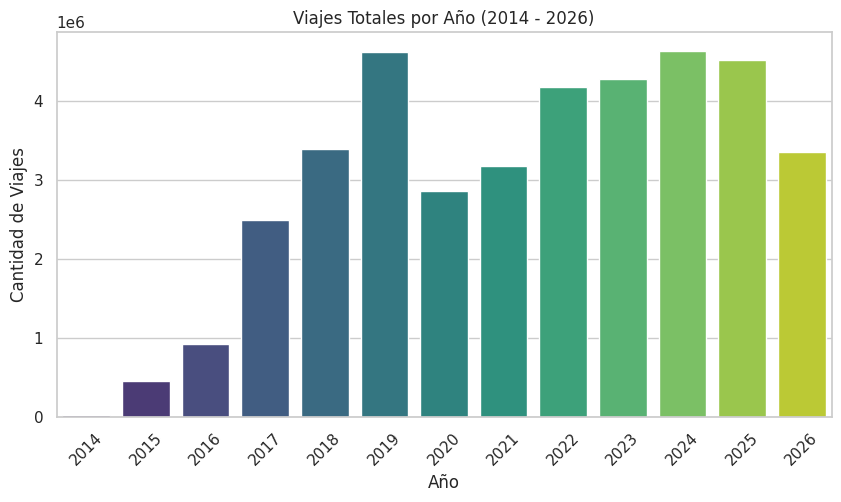

/tmp/ipykernel_3465/1668160158.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_origen_10.index.astype(str), y=top_origen_10.values, ax=axes[0], palette='magma')
/tmp/ipykernel_3465/1668160158.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_destino_10.index.astype(str), y=top_destino_10.values, ax=axes[1], palette='plasma')


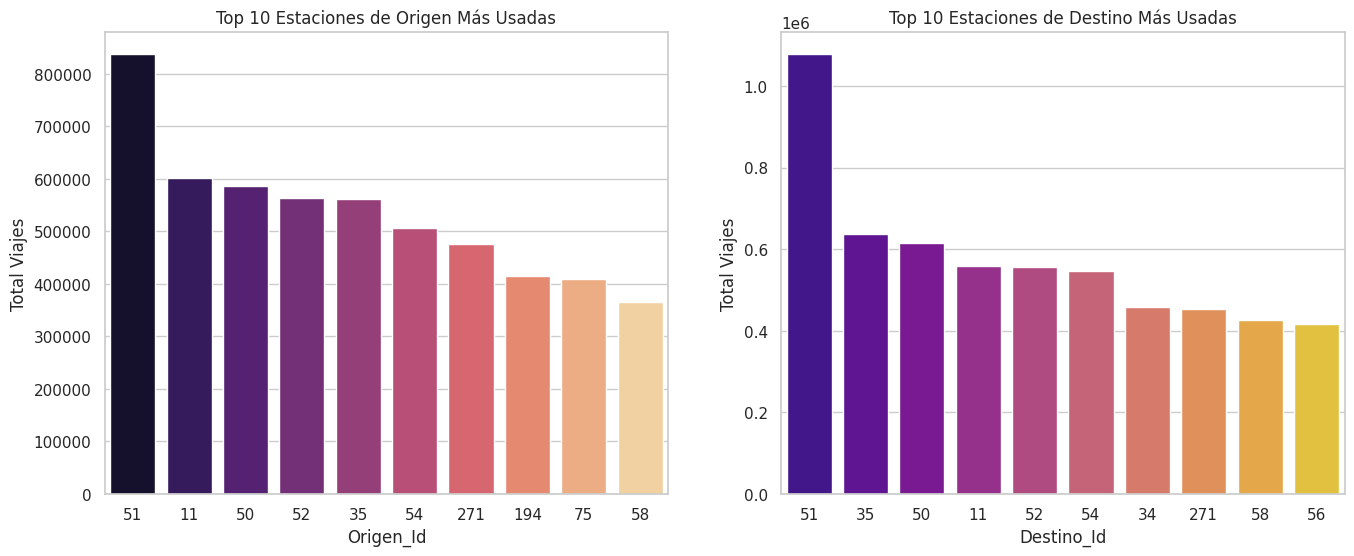

/tmp/ipykernel_3465/1668160158.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=viajes_por_hora.index.astype(int), y=viajes_por_hora.values, palette='coolwarm')


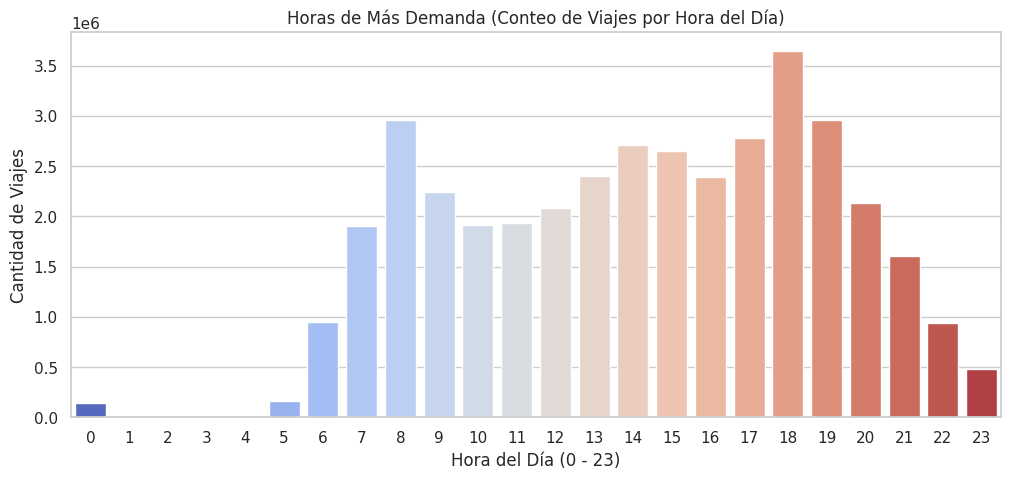

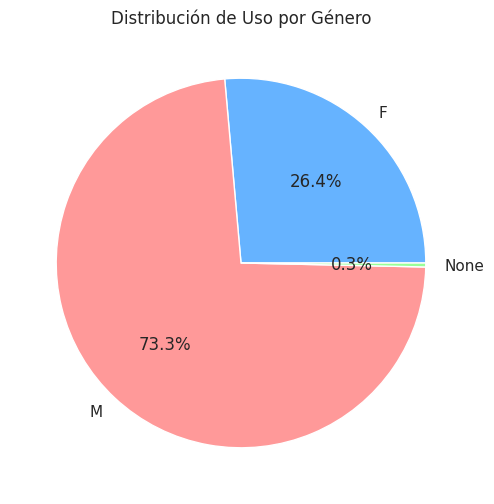

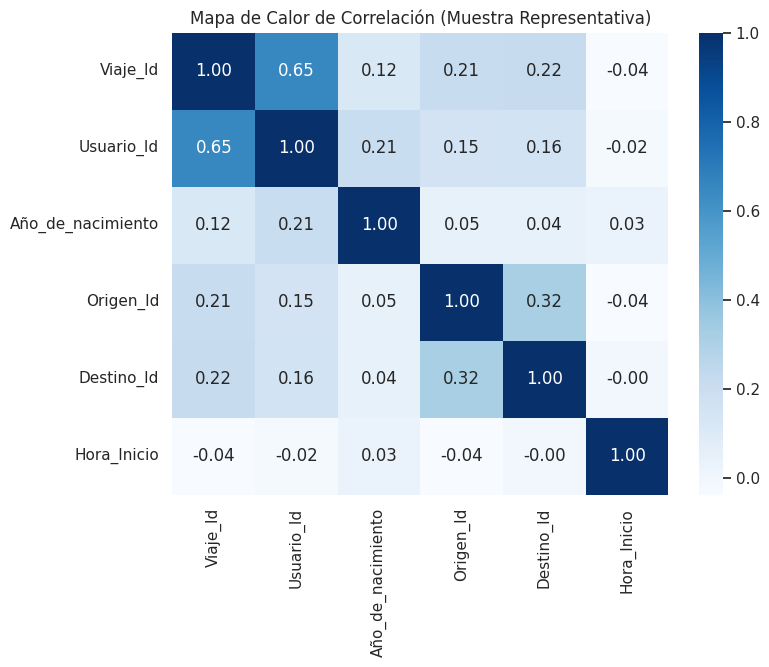

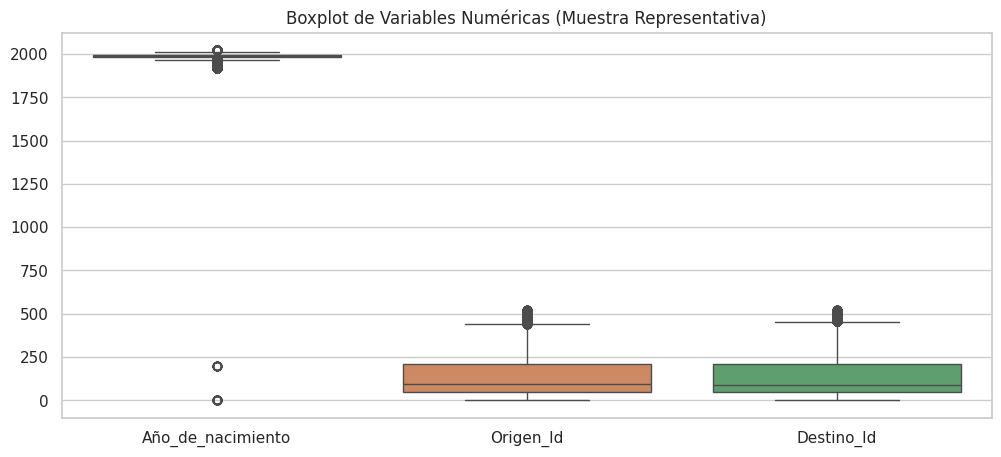

22434

In [ ]:
import os
import glob
import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

output_dir_processed = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed'
clean_files = sorted(glob.glob(os.path.join(output_dir_processed, 'df_clean_parte_*.parquet')))

print(f"Archivos limpios encontrados para EDA: {len(clean_files)}")

# ---------------------------------------------------------
# 1. ACUMULACIÓN INCREMENTAL DE MÉTRICAS (Mapeo por partes)
# ---------------------------------------------------------
viajes_por_año = pd.Series(dtype='int64')
top_origen = pd.Series(dtype='int64')
top_destino = pd.Series(dtype='int64')
viajes_por_hora = pd.Series(dtype='int64')
distribucion_genero = pd.Series(dtype='int64')

samples_list = [] # Para heatmap y boxplots

for idx, file_path in enumerate(clean_files, start=1):
    print(f"Procesando métricas de {os.path.basename(file_path)}...")
    df_part = pd.read_parquet(file_path, engine='pyarrow')

    # Conteo incremental
    años = df_part['Inicio_del_viaje'].dt.year.value_counts()
    horas = df_part['Inicio_del_viaje'].dt.hour.value_counts()
    origenes = df_part['Origen_Id'].value_counts()
    destinos = df_part['Destino_Id'].value_counts()
    generos = df_part['Genero'].value_counts()

    # Acumular conteos exactos
    viajes_por_año = viajes_por_año.add(años, fill_value=0)
    viajes_por_hora = viajes_por_hora.add(horas, fill_value=0)
    top_origen = top_origen.add(origenes, fill_value=0)
    top_destino = top_destino.add(destinos, fill_value=0)
    distribucion_genero = distribucion_genero.add(generos, fill_value=0)

    # Tomar muestra del 5% de cada parte para correlaciones y distribuciones contínuas
    sample_part = df_part[['Viaje_Id', 'Usuario_Id', 'Año_de_nacimiento', 'Origen_Id', 'Destino_Id']].sample(frac=0.05, random_state=42)
    sample_part['Hora_Inicio'] = df_part['Inicio_del_viaje'].dt.hour
    samples_list.append(sample_part)

    # Liberar memoria de la parte actual
    del df_part
    gc.collect()

# Formatear series agregadas
viajes_por_año = viajes_por_año.astype('int64').sort_index()
viajes_por_hora = viajes_por_hora.astype('int64').sort_index()
top_origen_10 = top_origen.astype('int64').nlargest(10)
top_destino_10 = top_destino.astype('int64').nlargest(10)
distribucion_genero = distribucion_genero.astype('int64')

# Consolidar muestra liviana para gráficos continuos
df_sample = pd.concat(samples_list, ignore_index=True)
del samples_list
gc.collect()

print("\n¡Agregación completada con éxito!")

# ---------------------------------------------------------
# 2. GENERACIÓN DE GRÁFICAS DEL EDA
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")

# A. Viajes por Año
plt.figure(figsize=(10, 5))
sns.barplot(x=viajes_por_año.index.astype(int), y=viajes_por_año.values, palette='viridis')
plt.title('Viajes Totales por Año (2014 - 2026)')
plt.xlabel('Año')
plt.ylabel('Cantidad de Viajes')
plt.xticks(rotation=45)
plt.show()

# B. Top 10 Estaciones de Origen y Destino
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=top_origen_10.index.astype(str), y=top_origen_10.values, ax=axes[0], palette='magma')
axes[0].set_title('Top 10 Estaciones de Origen Más Usadas')
axes[0].set_xlabel('Origen_Id')
axes[0].set_ylabel('Total Viajes')

sns.barplot(x=top_destino_10.index.astype(str), y=top_destino_10.values, ax=axes[1], palette='plasma')
axes[1].set_title('Top 10 Estaciones de Destino Más Usadas')
axes[1].set_xlabel('Destino_Id')
axes[1].set_ylabel('Total Viajes')
plt.show()

# C. Horas de más demanda
plt.figure(figsize=(12, 5))
sns.barplot(x=viajes_por_hora.index.astype(int), y=viajes_por_hora.values, palette='coolwarm')
plt.title('Horas de Más Demanda (Conteo de Viajes por Hora del Día)')
plt.xlabel('Hora del Día (0 - 23)')
plt.ylabel('Cantidad de Viajes')
plt.show()

# D. Distribución por Género
plt.figure(figsize=(6, 6))
plt.pie(distribucion_genero.values, labels=distribucion_genero.index, autopct='%1.1f%%', colors=['#66b3ff','#ff9999','#99ff99'])
plt.title('Distribución de Uso por Género')
plt.show()

# E. Mapa de Calor de Correlación
plt.figure(figsize=(8, 6))
sns.heatmap(df_sample.corr(), annot=True, cmap='Blues', fmt=".2f")
plt.title('Mapa de Calor de Correlación (Muestra Representativa)')
plt.show()

# F. Boxplots de Variables Numéricas
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_sample[['Año_de_nacimiento', 'Origen_Id', 'Destino_Id']])
plt.title('Boxplot de Variables Numéricas (Muestra Representativa)')
plt.show()

# Limpieza final de la muestra en RAM
del df_sample
gc.collect()

In [ ]:
import os
import glob
import gc
import pandas as pd

# Ruta de la carpeta con las partes limpias
output_dir_processed = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed'
clean_files = sorted(glob.glob(os.path.join(output_dir_processed, 'df_clean_parte_*.parquet')))

# Acumulador de registros por año
conteo_por_año = pd.Series(dtype='int64')

print(f"Analizando {len(clean_files)} partes limpias...")

for file_path in clean_files:
    # Cargar exclusivamente la columna 'Inicio_del_viaje' para ahorro máximo de RAM
    df_fecha = pd.read_parquet(file_path, columns=['Inicio_del_viaje'], engine='pyarrow')

    # Contar por año en esta parte
    conteos_parte = df_fecha['Inicio_del_viaje'].dt.year.value_counts()

    # Acumular al conteo global
    conteo_por_año = conteo_por_año.add(conteos_parte, fill_value=0)

    # Liberar memoria
    del df_fecha
    gc.collect()

# Formatear resultado
conteo_por_año = conteo_por_año.astype('int64').sort_index()

print("\n==========================================")
print(" REGISTROS TOTALES POR AÑO (DATAFRAME LIMPIO) ")
print("==========================================")
for año, total in conteo_por_año.items():
    print(f"Año {int(año)}: {total:>12,} registros")

print("------------------------------------------")
print(f"TOTAL GLOBAL: {conteo_por_año.sum():>10,} registros")
print("==========================================")

Analizando 3 partes limpias...

 REGISTROS TOTALES POR AÑO (DATAFRAME LIMPIO) 
Año 2014:       23,747 registros
Año 2015:      466,106 registros
Año 2016:      934,768 registros
Año 2017:    2,503,782 registros
Año 2018:    3,391,864 registros
Año 2019:    4,625,130 registros
Año 2020:    2,862,625 registros
Año 2021:    3,180,078 registros
Año 2022:    4,187,080 registros
Año 2023:    4,286,238 registros
Año 2024:    4,643,254 registros
Año 2025:    4,530,927 registros
Año 2026:    3,360,976 registros
------------------------------------------
TOTAL GLOBAL: 38,996,575 registros


Celda 5: Feature Engineering y Exportación del Dataset para ML (Pasos 4 y 5)

In [ ]:
import os
import glob
import gc
import json
import hashlib
import pandas as pd

output_dir_processed = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed'
output_dir_ml = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/ml_ready'
os.makedirs(output_dir_ml, exist_ok=True)

clean_files = sorted(glob.glob(os.path.join(output_dir_processed, 'df_clean_parte_*.parquet')))

print(f"Transformando {len(clean_files)} partes para Machine Learning...")

ml_files_created = []

for idx, file_path in enumerate(clean_files, start=1):
    print(f"Procesando Feature Engineering para Parte {idx}...")
    df_part = pd.read_parquet(file_path, engine='pyarrow')

    # 1. Feature Engineering de Fechas
    df_part['duracion_minutos'] = (df_part['Fin_del_viaje'] - df_part['Inicio_del_viaje']).dt.total_seconds() / 60.0
    df_part['hora_inicio'] = df_part['Inicio_del_viaje'].dt.hour
    df_part['dia_semana'] = df_part['Inicio_del_viaje'].dt.dayofweek
    df_part['mes'] = df_part['Inicio_del_viaje'].dt.month

    # Filtrar duraciones atípicas/negativas
    df_part = df_part[(df_part['duracion_minutos'] > 0) & (df_part['duracion_minutos'] <= 120)]

    # 2. One-Hot Encoding para Género
    df_encoded = pd.get_dummies(df_part, columns=['Genero'], prefix='gen', drop_first=True)

    # 3. Selección y conversión eficiente de columnas para ML
    cols_ml = ['duracion_minutos', 'hora_inicio', 'dia_semana', 'mes', 'Origen_Id', 'Destino_Id'] + [c for c in df_encoded.columns if c.startswith('gen_')]
    df_ml_part = df_encoded[cols_ml].copy()

    # Guardar parte ML
    ml_part_path = os.path.join(output_dir_ml, f'df_ml_parte_{idx}.parquet')
    df_ml_part.to_parquet(ml_part_path, index=False, engine='pyarrow')
    ml_files_created.append(ml_part_path)

    print(f"Parte {idx} de ML guardada en: {ml_part_path} ({len(df_ml_part):,} filas)")

    del df_part, df_encoded, df_ml_part
    gc.collect()

# ---------------------------------------------------------
# GENERACIÓN DE ARCHIVO METADATOS JSON (Paso 4 y 5)
# ---------------------------------------------------------
# Calcular Hash SHA-256 de la primera parte representativa
sha256_hash = hashlib.sha256()
with open(ml_files_created[0], "rb") as f:
    for byte_block in iter(lambda: f.read(4096), b""):
        sha256_hash.update(byte_block)

metadata = {
    "id": "dataset_ml_features_v1",
    "archivo": "df_ml_parte_1.parquet",
    "sha256": sha256_hash.hexdigest(),
    "url": f"https://drive.google.com/file/d/{ml_files_created[0]}",
    "origen": output_dir_processed,
    "transformaciones": [
        "Calculo de duracion_minutos a partir de datetimes (limite 0-120 min)",
        "Extraccion de hora_inicio, dia_semana y mes",
        "One-Hot Encoding de columna Genero"
    ],
    "commit": None
}

json_meta_path = os.path.join(output_dir_ml, 'metadata_ml_features.json')
with open(json_meta_path, 'w') as f:
    json.dump(metadata, f, indent=2)

print("\n¡Metadatos JSON creados exitosamente!")
print(json.dumps(metadata, indent=2))

Transformando 3 partes para Machine Learning...
Procesando Feature Engineering para Parte 1...
Parte 1 de ML guardada en: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/ml_ready/df_ml_parte_1.parquet (7,027,736 filas)
Procesando Feature Engineering para Parte 2...
Parte 2 de ML guardada en: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/ml_ready/df_ml_parte_2.parquet (14,421,820 filas)
Procesando Feature Engineering para Parte 3...
Parte 3 de ML guardada en: /content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/ml_ready/df_ml_parte_3.parquet (17,472,926 filas)

¡Metadatos JSON creados exitosamente!
{
  "id": "dataset_ml_features_v1",
  "archivo": "df_ml_parte_1.parquet",
  "sha256": "df39ec88640ac6d895ae092c05e33f1a2c1887dce2fc72a84319aebb264b13d0",
  "url": "https://drive.google.com/file/d//content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/ml_ready/df_ml_parte_1.parquet",
  "origen": "/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed",
  "transformaciones": [
    "Calc

Celda 6: Agregación de Balance y Regresión Lineal por Estación, Hora y Día (Paso 6)

Calculando balance de viajes por estación en cada parte...

Tabla de balance consolidada con éxito: 15,773,031 registros agrupados.

 RESULTADOS DEL MODELO DE REGRESIÓN LINEAL 
Mean Squared Error (MSE): 6.3891
R^2 Score:               0.0006


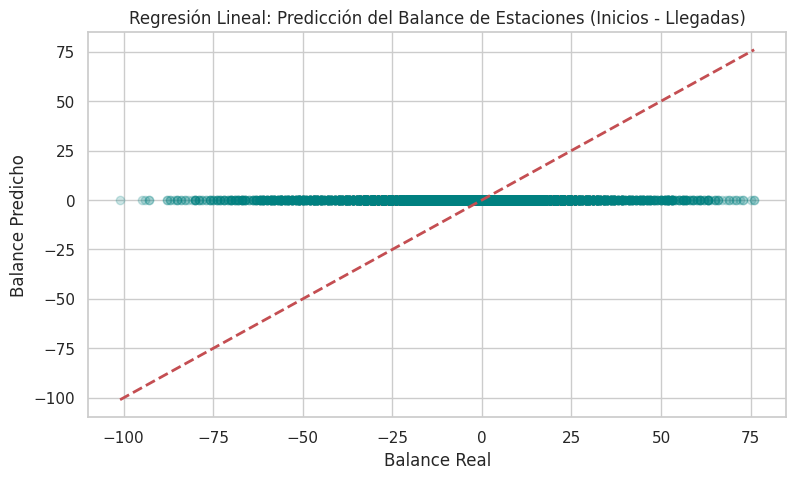

In [ ]:
import os
import glob
import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

output_dir_processed = '/content/drive/My Drive/MNA/MLOps/Proyecto_ML/data/processed'
clean_files = sorted(glob.glob(os.path.join(output_dir_processed, 'df_clean_parte_*.parquet')))

# DataFrames acumuladores de frecuencias
salidas_list = []
llegadas_list = []

print("Calculando balance de viajes por estación en cada parte...")

for file_path in clean_files:
    df_part = pd.read_parquet(file_path, engine='pyarrow')

    # Extraer variables clave de fecha/hora
    df_part['Fecha_Inicio'] = df_part['Inicio_del_viaje'].dt.date
    df_part['Hora_Inicio'] = df_part['Inicio_del_viaje'].dt.hour

    df_part['Fecha_Fin'] = df_part['Fin_del_viaje'].dt.date
    df_part['Hora_Fin'] = df_part['Fin_del_viaje'].dt.hour

    # Agrupar salidas por Estación, Fecha y Hora
    salidas = df_part.groupby(['Origen_Id', 'Fecha_Inicio', 'Hora_Inicio']).size().reset_index(name='inicios')
    salidas.columns = ['Estacion_Id', 'Fecha', 'Hora', 'Inicios']
    salidas_list.append(salidas)

    # Agrupar llegadas por Estación, Fecha y Hora
    llegadas = df_part.groupby(['Destino_Id', 'Fecha_Fin', 'Hora_Fin']).size().reset_index(name='llegadas')
    llegadas.columns = ['Estacion_Id', 'Fecha', 'Hora', 'Llegadas']
    llegadas_list.append(llegadas)

    del df_part
    gc.collect()

# Consolidar y sumar acumulados globales
df_salidas_all = pd.concat(salidas_list).groupby(['Estacion_Id', 'Fecha', 'Hora'])['Inicios'].sum().reset_index()
df_llegadas_all = pd.concat(llegadas_list).groupby(['Estacion_Id', 'Fecha', 'Hora'])['Llegadas'].sum().reset_index()

del salidas_list, llegadas_list
gc.collect()

# Consolidar Tabla de Balance (Inicios - Llegadas)
df_balance = pd.merge(df_salidas_all, df_llegadas_all, on=['Estacion_Id', 'Fecha', 'Hora'], how='outer').fillna(0)
df_balance['Balance'] = df_balance['Inicios'] - df_balance['Llegadas']

# Extraer Día de la Semana
df_balance['Fecha'] = pd.to_datetime(df_balance['Fecha'])
df_balance['Dia_Semana'] = df_balance['Fecha'].dt.dayofweek

print(f"\nTabla de balance consolidada con éxito: {len(df_balance):,} registros agrupados.")

# ---------------------------------------------------------
# ENTRENAMIENTO DEL MODELO DE REGRESIÓN LINEAL
# ---------------------------------------------------------
# Variables predictoras: Estacion_Id, Hora del día, Día de la semana
X = df_balance[['Estacion_Id', 'Hora', 'Dia_Semana']]
y = df_balance['Balance']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Métricas de evaluación
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n==========================================")
print(" RESULTADOS DEL MODELO DE REGRESIÓN LINEAL ")
print("==========================================")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 Score:               {r2:.4f}")

# Gráfica de Balance Real vs Predicción
plt.figure(figsize=(9, 5))
plt.scatter(y_test, y_pred, alpha=0.2, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Regresión Lineal: Predicción del Balance de Estaciones (Inicios - Llegadas)')
plt.xlabel('Balance Real')
plt.ylabel('Balance Predicho')
plt.show()